# 01 — Dữ liệu: vòng 1 so với vòng 2

Notebook này **chỉ đọc** dữ liệu đã dựng sẵn và vẽ — không gọi GPU, không tốn tiền, chạy lại lúc nào cũng được.

- Dữ liệu vòng 1: `data/processed/final/train_vi.jsonl` (đã train, cho điểm test 66–70%)
- Dữ liệu vòng 2: `data/processed/final_v2/train_vi.jsonl` — dựng bằng `python -m gen.dung_vong_2`

Câu hỏi notebook trả lời: **ba nguyên nhân gây lỗi ở vòng 1 đã được sửa trong dữ liệu chưa?**
1. Khoá từ vựng ("kính" chỉ thuộc về sấy kính)
2. Học tắt dạng câu ("cứ ra lệnh là gọi hàm")
3. Mẫu hỏi lại lệch (điều hoà chiếm 1/3, nhiều hàm gần như không có)

In [1]:
import json, os, sys
from collections import Counter
from pathlib import Path

# notebook nằm trong notebooks/ -> về thư mục gốc dự án để import được gen/, eval/
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(GOC); sys.path.insert(0, str(GOC))

import matplotlib.pyplot as plt
from gen.ra_soat_tu_vung import gom_cau, lech_dang_cau, lech_ham_hoi_lai
from gen.records import query_from_call_prompt

# Bảng màu: 2 chuỗi, đã chạy validate_palette.js (qua cả kiểm tra mù màu)
MAU = {"Vòng 1": "#2a78d6", "Vòng 2": "#eb6834"}
CHU_PHU = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def doc(p):
    with open(p, encoding="utf-8") as f:
        return [json.loads(x) for x in f if x.strip()]

V = {"Vòng 1": doc("data/processed/final/train_vi.jsonl"),
     "Vòng 2": doc("data/processed/final_v2/train_vi.jsonl")}
{k: len(v) for k, v in V.items()}

{'Vòng 1': 15942, 'Vòng 2': 16080}

## 1. Tổng quan: bao nhiêu mẫu, loại gì

In [2]:
def loai(r):
    if r["meta"]["fn"] == "irrelevant_function":
        return "từ chối"
    return {"call": "gọi hàm", "reply": "trả lời lượt 2", "ask": "hỏi lại"}[r["meta"]["type"]]

bang = {k: Counter(loai(r) for r in v) for k, v in V.items()}
cac_loai = ["gọi hàm", "trả lời lượt 2", "hỏi lại", "từ chối"]
print(f"{'':16}{'Vòng 1':>9}{'Vòng 2':>9}")
for l in cac_loai:
    print(f"{l:16}{bang['Vòng 1'][l]:>9}{bang['Vòng 2'][l]:>9}")
print(f"{'TỔNG':16}{len(V['Vòng 1']):>9}{len(V['Vòng 2']):>9}")

                   Vòng 1   Vòng 2
gọi hàm              6175     6279
trả lời lượt 2        993      881
hỏi lại               803      879
từ chối              7971     8041
TỔNG                15942    16080


## 2. Nguyên nhân ① — Khoá từ vựng

Vòng 1: **267/267** câu hạ kính chỉ dùng chữ "cửa sổ", còn chữ "kính" thuộc 100% về sấy kính → người nói
"hạ kính bên tài" thì model gọi sấy kính (đúng 8,3% trên test).

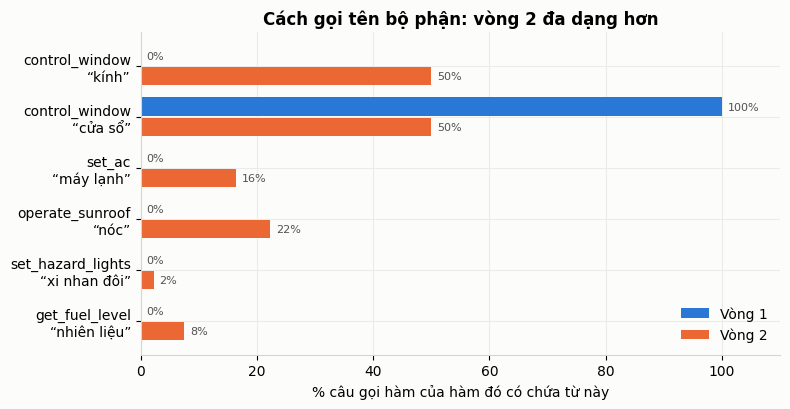

In [3]:
def ty_le_co_tu(rows, ham, tu):
    cau = [query_from_call_prompt(r["prompt"]).lower() for r in rows
           if r["meta"]["fn"] == ham and r["meta"]["type"] == "call"]
    return 100 * sum(1 for c in cau if tu in c) / max(len(cau), 1), len(cau)

CAP = [("control_window", "kính"), ("control_window", "cửa sổ"), ("set_ac", "máy lạnh"),
       ("operate_sunroof", "nóc"), ("set_hazard_lights", "xi nhan đôi"), ("get_fuel_level", "nhiên liệu")]
nhan = [f"{h}\n“{t}”" for h, t in CAP]
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(CAP))
for i, (k, rows) in enumerate(V.items()):
    gt = [ty_le_co_tu(rows, h, t)[0] for h, t in CAP]
    ax.barh([j + (-0.2 if i == 0 else 0.2) for j in y], gt, height=0.36, color=MAU[k], label=k)
    for j, g in zip(y, gt):
        ax.text(g + 1, j + (-0.2 if i == 0 else 0.2), f"{g:.0f}%", va="center", fontsize=8, color=CHU_PHU)
ax.set_yticks(list(y)); ax.set_yticklabels(nhan); ax.invert_yaxis()
ax.set_xlabel("% câu gọi hàm của hàm đó có chứa từ này"); ax.set_xlim(0, 110)
ax.set_title("Cách gọi tên bộ phận: vòng 2 đa dạng hơn"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 3. Nguyên nhân ② — Học tắt theo dạng câu

Vòng 1: câu mệnh lệnh gần như chỉ có ở mẫu gọi hàm → đoán "cứ ra lệnh là gọi hàm" đúng **94,7%** trên train →
model gọi bừa 17–19% câu ngoài phạm vi ("Bật sưởi ghế lái" → bật điều hoà). Càng gần 50% thì dạng câu càng ít
mách nước, model phải hiểu nghĩa.

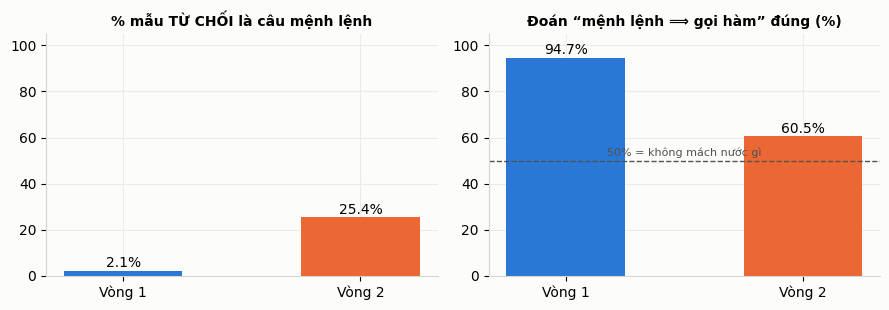

{'Vòng 1': {'so_mau_duong': 6978,
  'so_mau_am': 6842,
  'menh_lenh_duong_%': 37.1,
  'menh_lenh_am_%': 2.1,
  'goi_ham_dung_neu_doan_theo_menh_lenh_%': 94.7},
 'Vòng 2': {'so_mau_duong': 7158,
  'so_mau_am': 7126,
  'menh_lenh_duong_%': 38.7,
  'menh_lenh_am_%': 25.4,
  'goi_ham_dung_neu_doan_theo_menh_lenh_%': 60.5}}

In [4]:
dc = {k: lech_dang_cau(v) for k, v in V.items()}
chi_so = [("% mẫu TỪ CHỐI là câu mệnh lệnh", "menh_lenh_am_%"),
          ("Đoán “mệnh lệnh ⟹ gọi hàm” đúng (%)", "goi_ham_dung_neu_doan_theo_menh_lenh_%")]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (ten, khoa) in zip(axs, chi_so):
    gt = [dc[k][khoa] for k in V]
    ax.bar(list(V), gt, color=[MAU[k] for k in V], width=0.5)
    for i, g in enumerate(gt):
        ax.text(i, g + 1.5, f"{g:.1f}%", ha="center", fontsize=10)
    ax.set_title(ten, fontsize=10); ax.set_ylim(0, 105)
axs[1].axhline(50, color=CHU_PHU, lw=1, ls="--"); axs[1].text(0.5, 52, "50% = không mách nước gì", fontsize=8, color=CHU_PHU, ha="center")
plt.tight_layout(); plt.show()
dc

## 4. Nguyên nhân ③ — Mẫu hỏi lại lệch

Vòng 1: `set_ac` chiếm 37% mẫu hỏi lại; hàm nào có ≤ 34 mẫu thì trên test gần như luôn 0% (đường nét đứt).
Vòng 2: cắt trần 80 mẫu/hàm, thêm 4 hàm, và mọi mẫu đã qua quy trình chấm mới (xem PLAN.md E0b).

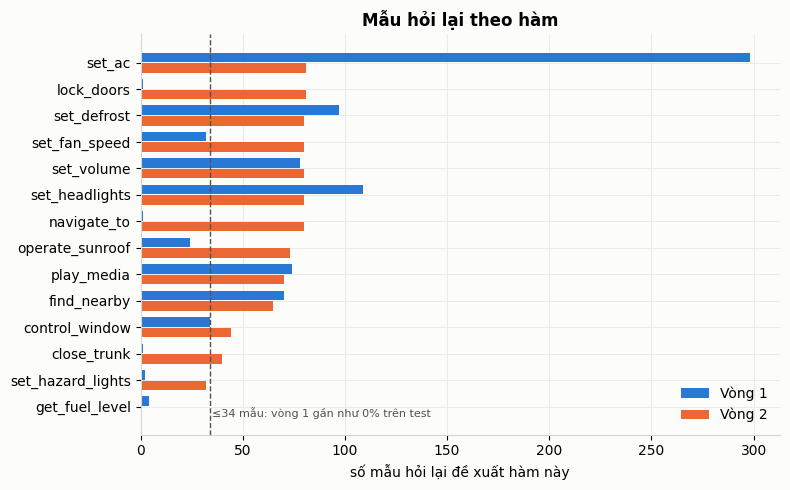

Vòng 2 vẫn dưới 34 mẫu: {'set_hazard_lights': 32, 'get_fuel_level': 0}


In [5]:
hl = {k: {h["ham"]: h["so_lan"] for h in lech_ham_hoi_lai(v)} for k, v in V.items()}
ham = sorted({h for d in hl.values() for h, n in d.items() if n}, key=lambda h: -hl["Vòng 2"].get(h, 0))
fig, ax = plt.subplots(figsize=(8, 5))
y = range(len(ham))
for i, k in enumerate(V):
    ax.barh([j + (-0.2 if i == 0 else 0.2) for j in y], [hl[k].get(h, 0) for h in ham],
            height=0.36, color=MAU[k], label=k)
ax.axvline(34, color=CHU_PHU, lw=1, ls="--")
ax.text(35, len(ham) - 0.6, "≤34 mẫu: vòng 1 gần như 0% trên test", fontsize=8, color=CHU_PHU)
ax.set_yticks(list(y)); ax.set_yticklabels(ham); ax.invert_yaxis()
ax.set_xlabel("số mẫu hỏi lại đề xuất hàm này"); ax.set_title("Mẫu hỏi lại theo hàm")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
mong = [h for h in ham if hl["Vòng 2"].get(h, 0) < 34]
print("Vòng 2 vẫn dưới 34 mẫu:", {h: hl["Vòng 2"].get(h, 0) for h in mong})

## 5. Câu từ chối dạng mệnh lệnh mới thêm (ngẫu nhiên 12 câu)

In [6]:
import random
kho = [query_from_call_prompt(r["prompt"]) for r in V["Vòng 2"] if r["meta"].get("nhom_phu") == "tu_choi_kho"]
print(len(kho), "câu trong train vòng 2\n")
for c in random.Random(1).sample(kho, 12):
    print("  •", c)

1667 câu trong train vòng 2

  • chỉnh gió ngoài lên
  • bật phanh tay tự động
  • chuyển sang bài hát trước lên
  • chỉnh ghế hành khách trở về vị trí 1
  • chuyển chế độ làm mát ghế sau sang mức thấp
  • cài đặt ga tự động 95 km/h
  • hạ rèm che nắng hộ cái
  • giảm cường độ phun nước rửa kính bên
  • gập gương hậu xuống
  • chỉnh phun nước rửa kính sau
  • hủy chức năng phanh tay điện tử
  • chuyển sang bài hát trước lên giúp tôi hộ cái


## 6. Tóm tắt

| | Vòng 1 | Vòng 2 |
|---|---|---|
| Khoá từ vựng | "kính" 0% ở hạ kính | xem mục 2 |
| Học tắt dạng câu | đoán tắt đúng 94,7% | xem mục 3 |
| Mẫu hỏi lại | `set_ac` 37%, 9 hàm | xem mục 4 |

**Đọc mục 4** để biết hàm nào còn dưới 34 mẫu hỏi lại. Dữ liệu tốt hơn không đồng nghĩa với model tốt hơn: chỉ tập test người viết trả lời được câu đó (notebook `03_danh_gia`).